In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA

workspace_root = next((path for path in [Path.cwd(), *Path.cwd().parents]
                       if (path / "data" / "raw").exists()), Path.cwd())
data_dir = workspace_root / "data" / "raw"
cols = [f"pixel_{i}" for i in range(64)] + ["target"]
train = pd.read_csv(data_dir / "optdigits.tra", header=None, names=cols)
test  = pd.read_csv(data_dir / "optdigits.tes", header=None, names=cols)
print("Loaded - train:", train.shape, "test:", test.shape)

Loaded - train: (3823, 65) test: (1797, 65)


## Step 1: Data Cleaning
Confirm no missing values, remove duplicates, validate pixel range 0-16.

In [2]:
assert train.isnull().sum().sum() == 0, "Unexpected missing values found"
assert test.isnull().sum().sum() == 0, "Unexpected missing values found"

n_before = train.shape[0]
train = train.drop_duplicates().reset_index(drop=True)
print("Duplicates removed from train:", n_before - train.shape[0])  # run this code to obtain actual value

assert ((train.iloc[:, :64] >= 0) & (train.iloc[:, :64] <= 16)).all().all(), "Out-of-range pixel values found"
assert ((test.iloc[:, :64] >= 0) & (test.iloc[:, :64] <= 16)).all().all(), "Out-of-range pixel values found"
print("Step 1 complete: no missing values, duplicates removed, range validated.")


Duplicates removed from train: 0
Step 1 complete: no missing values, duplicates removed, range validated.


## Step 2: Outlier Removal
Remove rows whose total pixel intensity is an IQR outlier. **Fit bounds on TRAIN only** and apply the same fixed bounds to test (never recompute quantiles on test - that would leak test distribution info into the pipeline).

In [3]:
train["total_intensity"] = train.iloc[:, :64].sum(axis=1)
test["total_intensity"]  = test.iloc[:, :64].sum(axis=1)

Q1, Q3 = train["total_intensity"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR

train_mask = (train["total_intensity"] >= lower) & (train["total_intensity"] <= upper)
train = train[train_mask].reset_index(drop=True)
print("Train rows after outlier removal:", train.shape[0])  # run this code to obtain actual value
# NOTE: we do NOT drop rows from test - test set composition must stay fixed for fair evaluation.


Train rows after outlier removal: 3820


## Step 3: Feature Scaling
Fit `MinMaxScaler` on train only, transform both.

In [4]:
feature_cols = [c for c in train.columns if c.startswith("pixel_")]

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(train[feature_cols])
X_test_scaled  = scaler.transform(test[feature_cols])
print("Scaled train shape:", X_train_scaled.shape)  # run this code to obtain actual value


Scaled train shape: (3820, 64)


## Step 4: Feature Selection
Fit `VarianceThreshold` and correlation filtering on train only, apply same column set to test.

In [5]:
selector = VarianceThreshold(threshold=0.05)
X_train_var = selector.fit_transform(X_train_scaled)
X_test_var  = selector.transform(X_test_scaled)
kept_cols = [c for c, keep in zip(feature_cols, selector.get_support()) if keep]

corr = pd.DataFrame(X_train_var, columns=kept_cols).corr().abs()
upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper_tri.columns if any(upper_tri[c] > 0.9)]
final_cols = [c for c in kept_cols if c not in to_drop]

train_selected_idx = [kept_cols.index(c) for c in final_cols]
X_train_sel = X_train_var[:, train_selected_idx]
X_test_sel  = X_test_var[:, train_selected_idx]
print("Final feature count after selection:", X_train_sel.shape[1])  # run this code to obtain actual value


Final feature count after selection: 38


## Step 5: Dimensionality Reduction (PCA)
Fit PCA on the selected, scaled TRAIN features only; transform test with the same fitted PCA.

In [6]:
pca_full = PCA().fit(X_train_sel)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.argmax(cum_var >= 0.95) + 1)

pca = PCA(n_components=n_components_95)
X_train_pca = pca.fit_transform(X_train_sel)
X_test_pca  = pca.transform(X_test_sel)
print("Components retained for 95% variance:", n_components_95)  # run this code to obtain actual value
print("Final train shape:", X_train_pca.shape, "| Final test shape:", X_test_pca.shape)  # run this code to obtain actual value


Components retained for 95% variance: 25
Final train shape: (3820, 25) | Final test shape: (1797, 25)


## Step 6: Feature Encoding
One-hot encode the target column, fit on train's known classes (0-9).

In [7]:
encoder = OneHotEncoder(sparse_output=False, categories=[list(range(10))])
y_train_onehot = encoder.fit_transform(train[["target"]])
y_test_onehot  = encoder.transform(test[["target"]])
print("y_train_onehot shape:", y_train_onehot.shape)  # run this code to obtain actual value


y_train_onehot shape: (3820, 10)


## Final EDA snapshot on the fully processed data

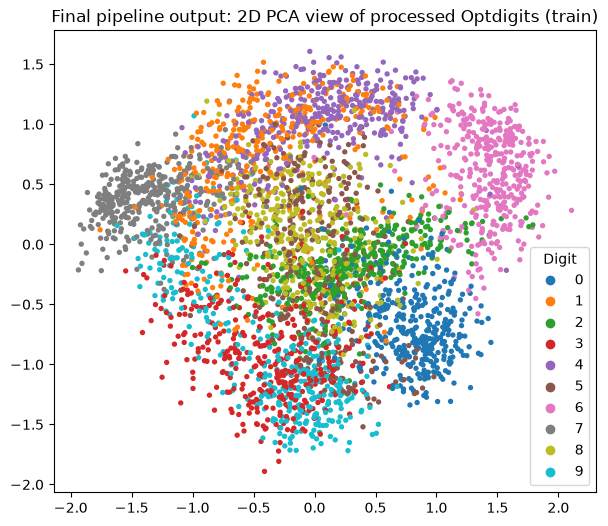

In [8]:
plt.figure(figsize=(7,6))
scatter = plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=train["target"], cmap="tab10", s=8)
plt.legend(*scatter.legend_elements(), title="Digit")
plt.title("Final pipeline output: 2D PCA view of processed Optdigits (train)")
plt.savefig(workspace_root / "results" / "eda_visualizations" / "group_final_pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

## Save final processed dataset

In [9]:
final_train = pd.DataFrame(X_train_pca, columns=[f"pc_{i}" for i in range(X_train_pca.shape[1])])
final_train["target"] = train["target"].values
final_test = pd.DataFrame(X_test_pca, columns=[f"pc_{i}" for i in range(X_test_pca.shape[1])])
final_test["target"] = test["target"].values

processed_dir = workspace_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
final_train.to_csv(processed_dir / "optdigits_train_processed.csv", index=False)
final_test.to_csv(processed_dir / "optdigits_test_processed.csv", index=False)
print(f"Saved processed train/test sets to {processed_dir}")

Saved processed train/test sets to c:\Users\Admin\OneDrive\Desktop\AIML Project\B11-G1-8\data\processed


## Pipeline summary
| Step | Member | Technique | Leakage-safe? |
|---|---|---|---|
| 1 | Data Cleaning | Data cleaning (dedupe/validate) | Duplicates removed from train only |
| 2 | Outlier Removal | Outlier removal | IQR bounds computed on train only |
| 3 | MinMax Scaling | MinMax scaling | `fit_transform` train, `transform` test |
| 4 | Feature Selection | Feature selection | Fit on train, same columns applied to test |
| 5 | Dimensionality Reduction (PCA) | PCA | Fit on train, `transform` test |
| 6 | Feature Encoding | Target one-hot encoding | Fixed category list (0-9) |
